# The nibble challenge
A nibble is four binary digits. We will teach a 4 → 8 → 1 network to convert them into a decimal value, then inspect how its weights and activations change.

Follow the [project setup instructions](README.md), then open this notebook with Jupyter. Select your Neuralplex Python environment. The kernel working directory should be this notebook's directory so `from visualizations import ...` finds its neighboring module.

Run the cells in order. To change the seed, learning rate, or training budget, **restart the kernel and run all cells**. Re-running only training continues from the existing weights.


In [1]:
%matplotlib inline
from copy import deepcopy
from random import Random

import matplotlib.pyplot as plt
from IPython.display import display
from neuralplex import Network, Layer, Neuron
from visualizations import visualize_network


## 1. Examine the problem
Each bit has a place value: `8, 4, 2, 1`. Conversion is a weighted sum, so linear activations suffice. The hidden layer is included to make backpropagation visible; this task does not require one.

All sixteen inputs are part of this demonstration. This is not a held-out generalization benchmark.


In [2]:
examples = [([int(bit) for bit in f'{number:04b}'], number) for number in range(16)]
for bits, number in examples:
    print(bits, '→', number)


[0, 0, 0, 0] → 0
[0, 0, 0, 1] → 1
[0, 0, 1, 0] → 2
[0, 0, 1, 1] → 3
[0, 1, 0, 0] → 4
[0, 1, 0, 1] → 5
[0, 1, 1, 0] → 6
[0, 1, 1, 1] → 7
[1, 0, 0, 0] → 8
[1, 0, 0, 1] → 9
[1, 0, 1, 0] → 10
[1, 0, 1, 1] → 11
[1, 1, 0, 0] → 12
[1, 1, 0, 1] → 13
[1, 1, 1, 0] → 14
[1, 1, 1, 1] → 15


## 2. Choose parameters and construct the network
Each computational neuron has one bias and a separate weight for every incoming connection. Input neurons hold the four raw bits. Names make the network easier to inspect and visualize.


In [3]:
SEED = 42
STEP = 0.01
ITERATIONS = 10000

network = Network([
    Layer([Neuron(name=f'i{i}') for i in range(4)]),
    Layer([Neuron(name=f'h{i}') for i in range(8)], step=STEP),
    Layer([Neuron(name='output')], step=STEP),
], seed=SEED)
before = deepcopy(network)
rng = Random(SEED)


## 3. Predict before training
The initial connections are random. Keep a copy so we can compare the same input before and after learning.


In [4]:
initial_predictions = [before.predict(bits)[0] for bits, number in examples]
print('Initial prediction for 1010:', before.predict([1, 0, 1, 0]))


Initial prediction for 1010: [0.016680184836415125]


## 4. Train one example at a time
Each `train` call performs a forward pass, calculates gradients backward, and then updates parameters. The loss is half the sum of squared output errors.


In [5]:
for iteration in range(ITERATIONS):
    bits, number = rng.choice(examples)
    network.train(bits, [number])
    if (iteration + 1) % 1000 == 0:
        print(f'Training iteration: {iteration + 1}')


Training iteration: 1000
Training iteration: 2000
Training iteration: 3000
Training iteration: 4000
Training iteration: 5000


Training iteration: 6000


Training iteration: 7000


Training iteration: 8000
Training iteration: 9000
Training iteration: 10000


## 5. Evaluate all sixteen nibbles
Compare the predictions and mean squared error.


In [6]:
predictions = [network.predict(bits)[0] for bits, number in examples]
print('Nibble  Truth     Before      After')
for (bits, number), initial, prediction in zip(examples, initial_predictions, predictions):
    print(f'{number:04b}    {number:2d}    {initial:9.4f}  {prediction:9.4f}')
initial_error = sum((p - number)**2 for p, (_, number) in zip(initial_predictions, examples))
final_error = sum((p - number)**2 for p, (_, number) in zip(predictions, examples))
r2 = 1 - final_error / sum((number - 7.5)**2 for _, number in examples)
print(f'Mean squared error: {initial_error / 16:.6f} → {final_error / 16:.6f}')
print(f'R²: {r2:.9f}')


Nibble  Truth     Before      After
0000     0       0.0000    -0.0000
0001     1      -0.0214     1.0000
0010     2       0.0072     2.0000
0011     3      -0.0143     3.0000
0100     4       0.0044     4.0000
0101     5      -0.0170     5.0000
0110     6       0.0115     6.0000
0111     7      -0.0099     7.0000
1000     8       0.0095     8.0000
1001     9      -0.0119     9.0000
1010    10       0.0167    10.0000
1011    11      -0.0047    11.0000
1100    12       0.0139    12.0000
1101    13      -0.0075    13.0000
1110    14       0.0211    14.0000
1111    15      -0.0003    15.0000
Mean squared error: 77.459411 → 0.000000
R²: 1.000000000


## 6. Explore a particular input
Change `input_bits` and rerun this cell and the following visualization cell. Edge weights stay fixed; activations depend on the input. The table shows the actual parameters and signed activations.


In [7]:
input_bits = [1, 0, 1, 0]
print('Prediction:', network.predict(input_bits))
for layer in network.layers:
    for neuron in layer.neurons:
        weights = {source.name: round(weight, 4) for source, weight in neuron.weights.items()}
        print(neuron.name, 'activation:', round(neuron.value, 4),
              'bias:', round(neuron.bias, 4), 'incoming weights:', weights)


Prediction: [10.0]
i0 activation: 1 bias: 0 incoming weights: {}
i1 activation: 0 bias: 0 incoming weights: {}
i2 activation: 1 bias: 0 incoming weights: {}
i3 activation: 0 bias: 0 incoming weights: {}
h0 activation: -0.8214 bias: 0.1339 incoming weights: {'i0': -0.7432, 'i1': -0.4529, 'i2': -0.212, 'i3': -0.1658}
h1 activation: 1.8193 bias: -0.2701 incoming weights: {'i0': 1.6522, 'i1': 0.8013, 'i2': 0.4372, 'i3': 0.1716}
h2 activation: -1.274 bias: 0.2122 incoming weights: {'i0': -1.1771, 'i1': -0.6384, 'i2': -0.3091, 'i3': -0.1717}
h3 activation: -0.4756 bias: 0.1403 incoming weights: {'i0': -0.5557, 'i1': -0.267, 'i2': -0.0601, 'i3': -0.0487}
h4 activation: 0.6108 bias: -0.0397 incoming weights: {'i0': 0.4625, 'i1': 0.2755, 'i2': 0.1881, 'i3': -0.0024}
h5 activation: 0.3624 bias: -0.0876 incoming weights: {'i0': 0.4078, 'i1': 0.2022, 'i2': 0.0421, 'i3': -0.0161}
h6 activation: 0.4512 bias: -0.0841 incoming weights: {'i0': 0.5162, 'i1': 0.1778, 'i2': 0.0191, 'i3': -0.005}
h7 activa

## 7. Visualize before and after
The helper is imported from the neighboring `visualizations.py`. Both panels use the same input, positions, and scales. Blue edges are positive; orange edges are negative. Thickness shows absolute weight. Node area above a small visibility floor shows absolute activation—not importance. Input, hidden, and output nodes are green, red, and yellow.

The helper copies the models before calculating the displayed activations; it does not modify or train them.


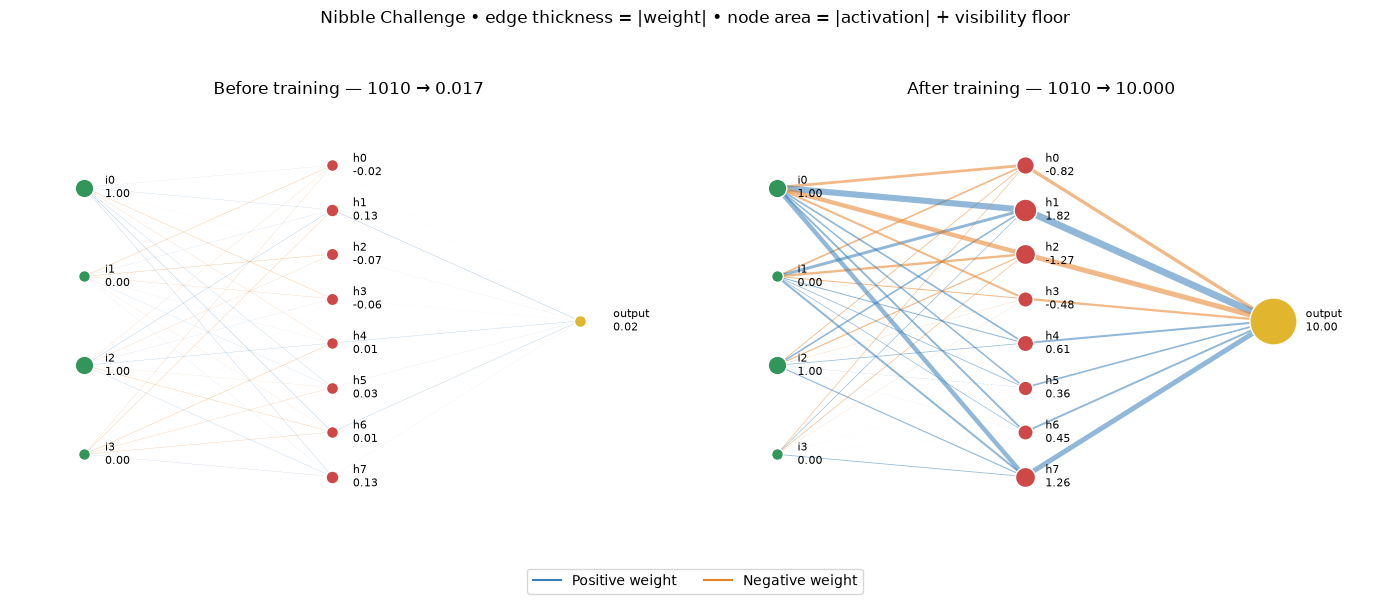

In [8]:
network_figure = visualize_network(before, network, input_bits)
display(network_figure)
plt.close(network_figure)


## Things to try
- Reduce `ITERATIONS` and inspect the imperfect predictions.
- Change `STEP`, then restart and run all cells to compare fairly.
- Change the hidden-layer size and inspect the connections.
- Try each input nibble and observe that weights stay fixed while activations change.
